<a href="https://colab.research.google.com/github/hyhyhy1105-cyber/fish-spoon/blob/main/garbage_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

사용 장치: cuda
Using Colab cache for faster access to the 'garbage-classification' dataset.
총 클래스 개수: 12개, 총 이미지 수: 15515장


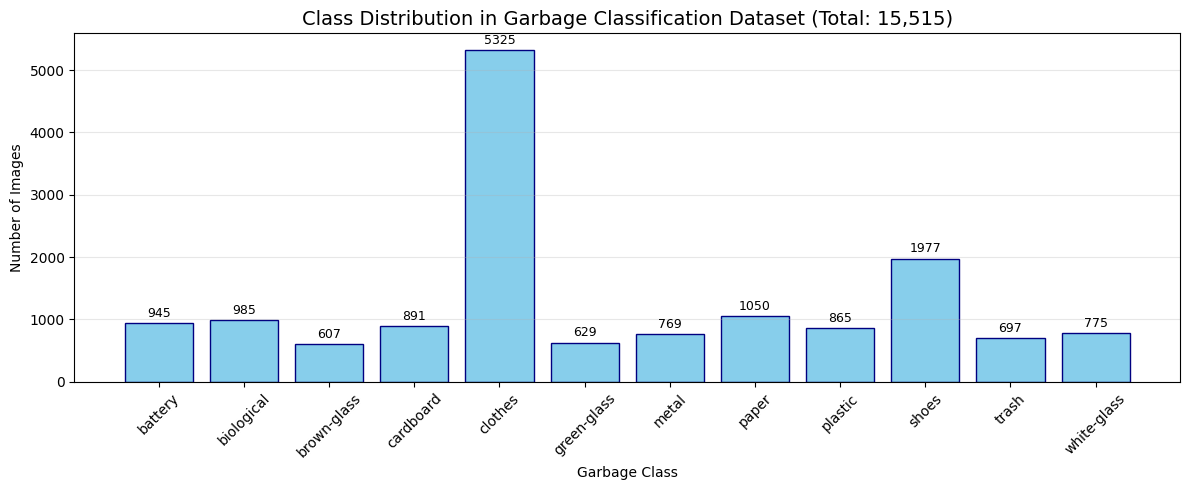

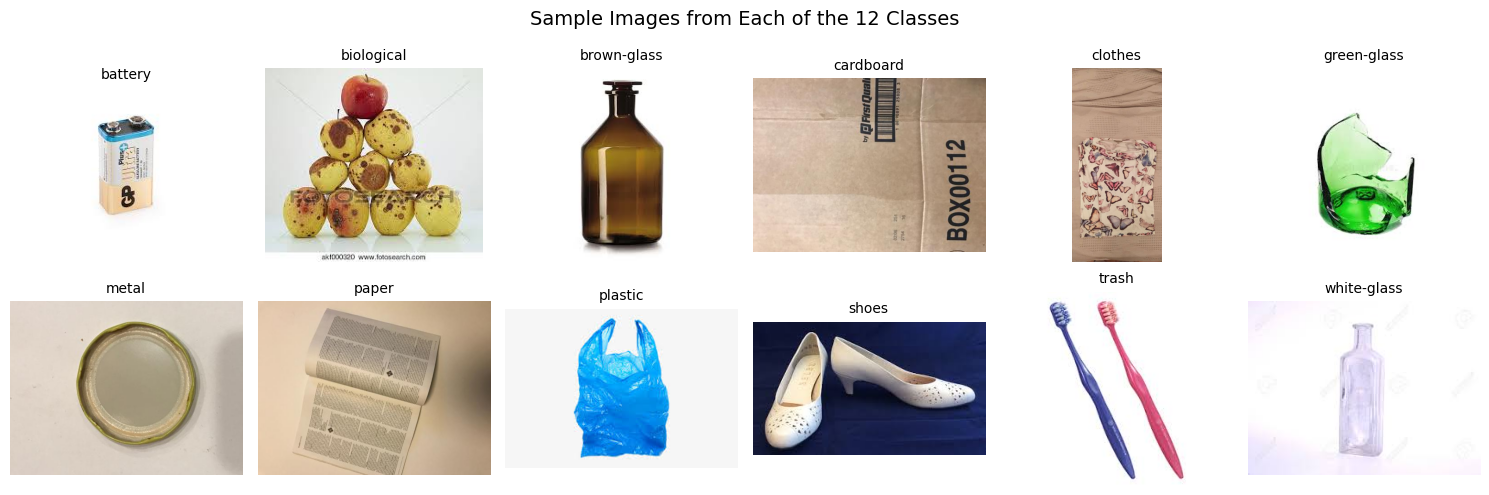

In [1]:
import os
import time
import copy
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# 1. 재현성을 위한 시드 고정 & GPU 장치 설정 (4주차, 9주차 내용)
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

# 2. 데이터셋 다운로드
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
data_dir = os.path.join(path, "garbage_classification")

class_names = sorted(os.listdir(data_dir))
class_counts = {cls: len(os.listdir(os.path.join(data_dir, cls))) for cls in class_names}
print(f"총 클래스 개수: {len(class_names)}개, 총 이미지 수: {sum(class_counts.values())}장")

# 3. [보고서 그림 1] 클래스별 이미지 분포 막대그래프
plt.figure(figsize=(12, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(), color="skyblue", edgecolor="navy")
plt.title("Class Distribution in Garbage Classification Dataset (Total: 15,515)", fontsize=14)
plt.xlabel("Garbage Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, int(yval), ha='center', va='bottom', fontsize=9)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 4. [보고서 그림 2] 12개 클래스별 대표 샘플 이미지 출력
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for idx, cls in enumerate(class_names):
    cls_folder = os.path.join(data_dir, cls)
    sample_img_path = os.path.join(cls_folder, os.listdir(cls_folder)[0])
    img = plt.imread(sample_img_path)
    ax = axes[idx // 6, idx % 6]
    ax.imshow(img)
    ax.set_title(cls, fontsize=10)
    ax.axis("off")
plt.suptitle("Sample Images from Each of the 12 Classes", fontsize=14)
plt.tight_layout()
plt.show()

In [2]:
# 1. 기본 전처리 및 데이터 분할: Train(70%) / Val(15%) / Test(15%) (5주차 random_split)
transform_basic = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

full_dataset = datasets.ImageFolder(root=data_dir, transform=transform_basic)
total_size = len(full_dataset)
train_size = int(total_size * 0.7)
val_size = int(total_size * 0.15)
test_size = total_size - train_size - val_size

torch.manual_seed(42)
train_ds, val_ds, test_ds = random_split(full_dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# 2. 기본 CNN 모델 정의 (8주차 CNN 구조: 규제/증강 없음)
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2), # 128 -> 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2), # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2), # 32 -> 16
        )
        with torch.no_grad():
            flat_size = self.features(torch.zeros(1, 3, 128, 128)).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_size, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_base = BaselineCNN(num_classes=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_base.parameters(), lr=0.001)

# 3. 기본 모델 10 Epoch 학습 (과적합 확인)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print("🚀 [BaselineCNN] 학습 시작 (과적합 확인용)")
for epoch in range(10):
    model_base.train()
    tr_loss, tr_corr = 0.0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        pred = model_base(bx)
        loss = loss_fn(pred, by)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * bx.size(0)
        tr_corr += (pred.argmax(dim=1) == by).sum().item()

    model_base.eval()
    va_loss, va_corr = 0.0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model_base(bx)
            loss = loss_fn(pred, by)
            va_loss += loss.item() * bx.size(0)
            va_corr += (pred.argmax(dim=1) == by).sum().item()

    t_l, v_l = tr_loss / train_size, va_loss / val_size
    t_a, v_a = tr_corr / train_size, va_corr / val_size
    history["train_loss"].append(t_l); history["val_loss"].append(v_l)
    history["train_acc"].append(t_a); history["val_acc"].append(v_a)

    print(f"Epoch [{epoch+1:2d}/10] Train Loss: {t_l:.4f}, Acc: {t_a:.4f} | Val Loss: {v_l:.4f}, Acc: {v_a:.4f}")

🚀 [BaselineCNN] 학습 시작 (과적합 확인용)
Epoch [ 1/10] Train Loss: 1.4796, Acc: 0.5097 | Val Loss: 1.1357, Acc: 0.6038
Epoch [ 2/10] Train Loss: 0.9682, Acc: 0.6797 | Val Loss: 0.9449, Acc: 0.6755
Epoch [ 3/10] Train Loss: 0.7721, Acc: 0.7429 | Val Loss: 0.8329, Acc: 0.7211
Epoch [ 4/10] Train Loss: 0.6188, Acc: 0.7967 | Val Loss: 0.7926, Acc: 0.7465
Epoch [ 5/10] Train Loss: 0.4846, Acc: 0.8398 | Val Loss: 0.7976, Acc: 0.7447
Epoch [ 6/10] Train Loss: 0.3790, Acc: 0.8776 | Val Loss: 0.7919, Acc: 0.7538
Epoch [ 7/10] Train Loss: 0.2443, Acc: 0.9195 | Val Loss: 0.8949, Acc: 0.7516
Epoch [ 8/10] Train Loss: 0.1760, Acc: 0.9446 | Val Loss: 1.0439, Acc: 0.7336
Epoch [ 9/10] Train Loss: 0.1215, Acc: 0.9610 | Val Loss: 1.0810, Acc: 0.7576
Epoch [10/10] Train Loss: 0.0941, Acc: 0.9700 | Val Loss: 1.2209, Acc: 0.7443


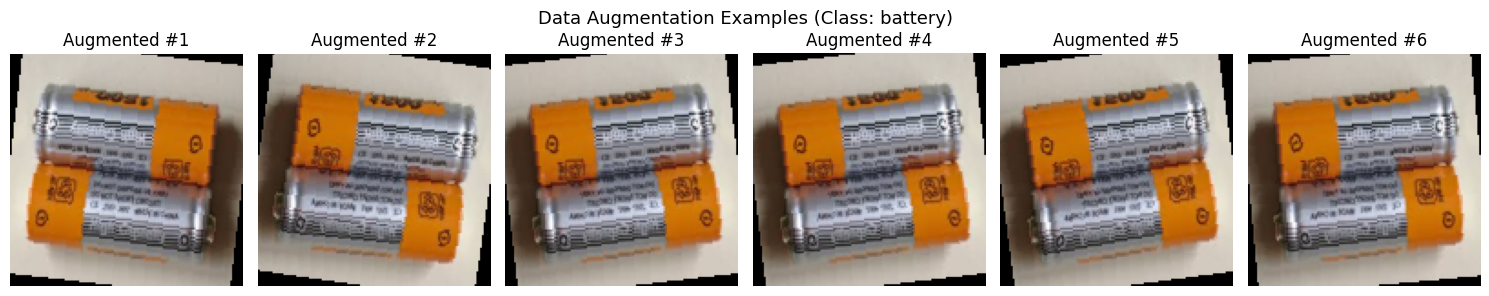


🚀 [Exp1_Improved_Base] 시작 (lr=0.001, batch=64, opt=Adam)
  Epoch [ 5/15] Train Acc: 0.5265, Val Loss: 1.0745, Val Acc: 0.6317
  Epoch [10/15] Train Acc: 0.5675, Val Loss: 0.9429, Val Acc: 0.6859
  Epoch [15/15] Train Acc: 0.6011, Val Loss: 0.9617, Val Acc: 0.6850

🚀 [Exp2_Lower_LR] 시작 (lr=0.0003, batch=64, opt=Adam)
  Epoch [ 5/15] Train Acc: 0.6774, Val Loss: 0.7989, Val Acc: 0.7220
  Epoch [10/15] Train Acc: 0.7295, Val Loss: 0.7020, Val Acc: 0.7731
  Epoch [15/15] Train Acc: 0.7616, Val Loss: 0.6244, Val Acc: 0.8032

🚀 [Exp3_Batch32] 시작 (lr=0.001, batch=32, opt=Adam)
  Epoch [ 5/15] Train Acc: 0.5569, Val Loss: 1.0580, Val Acc: 0.6502
  Epoch [10/15] Train Acc: 0.6180, Val Loss: 0.8682, Val Acc: 0.7086
  Epoch [15/15] Train Acc: 0.6609, Val Loss: 0.7761, Val Acc: 0.7512

📊 [하이퍼파라미터 비교 실험 결과표]


,실험명,Learning Rate,Batch Size,Optimizer,최고 Val Acc,최종 Val Loss,과적합 격차(Train-Val),소요 시간(초)
0,Exp1_Improved_Base,0.0010,64,Adam,0.7000,0.9617,-0.0839,505.7
1,Exp2_Lower_LR,0.0003,64,Adam,0.8032,0.6244,-0.0416,507.8
2,Exp3_Batch32,0.0010,32,Adam,0.7512,0.7761,-0.0903,524.5


In [3]:
# 1. 데이터 증강 설정: Train에만 증강 적용, Val/Test에는 미적용 (9주차 실습 04)
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

transform_eval = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

base_dataset = datasets.ImageFolder(root=data_dir)
torch.manual_seed(42)
train_idx, val_idx, test_idx = random_split(range(len(base_dataset)), [train_size, val_size, test_size])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.dataset[self.indices[idx]]
        if self.transform:
            img = self.transform(img)
        return img, label

train_ds_aug = TransformSubset(base_dataset, train_idx, transform=transform_train)
val_ds_clean = TransformSubset(base_dataset, val_idx, transform=transform_eval)
test_ds_clean = TransformSubset(base_dataset, test_idx, transform=transform_eval)

# [보고서 그림 3] 데이터 증강 적용 모습 시각화
sample_pil, sample_label = base_dataset[0]
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i in range(6):
    aug_tensor = transform_train(sample_pil)
    axes[i].imshow(aug_tensor.permute(1, 2, 0).numpy())
    axes[i].set_title(f"Augmented #{i+1}")
    axes[i].axis("off")
plt.suptitle(f"Data Augmentation Examples (Class: {class_names[sample_label]})", fontsize=13)
plt.tight_layout()
plt.show()

# 2. 개선된 CNN 모델: BatchNorm2d + Dropout(0.5) 적용 (9주차 실습 02, 03)
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=12, dropout_p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        with torch.no_grad():
            flat_size = self.features(torch.zeros(1, 3, 128, 128)).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_p),
            nn.Linear(flat_size, 256),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# 3. 조건 고정 하이퍼파라미터 실험 함수
def run_experiment(exp_name, lr=0.001, batch_size=64, opt_type="Adam", dropout_p=0.5, epochs=15):
    print(f"\n🚀 [{exp_name}] 시작 (lr={lr}, batch={batch_size}, opt={opt_type})")
    torch.manual_seed(42)
    t_loader = DataLoader(train_ds_aug, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    v_loader = DataLoader(val_ds_clean, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    model = ImprovedCNN(num_classes=len(class_names), dropout_p=dropout_p).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) if opt_type == "Adam" else torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        tr_loss, tr_corr = 0.0, 0
        for bx, by in t_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx)
            loss = loss_fn(pred, by)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * bx.size(0)
            tr_corr += (pred.argmax(dim=1) == by).sum().item()

        model.eval()
        va_loss, va_corr = 0.0, 0
        with torch.no_grad():
            for bx, by in v_loader:
                bx, by = bx.to(device), by.to(device)
                pred = model(bx)
                loss = loss_fn(pred, by)
                va_loss += loss.item() * bx.size(0)
                va_corr += (pred.argmax(dim=1) == by).sum().item()

        t_l, v_l = tr_loss / len(train_ds_aug), va_loss / len(val_ds_clean)
        t_a, v_a = tr_corr / len(train_ds_aug), va_corr / len(val_ds_clean)
        hist["train_loss"].append(t_l); hist["val_loss"].append(v_l)
        hist["train_acc"].append(t_a); hist["val_acc"].append(v_a)

        if v_a > best_val_acc:
            best_val_acc = v_a
            best_model_wts = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0:
            print(f"  Epoch [{epoch+1:2d}/{epochs}] Train Acc: {t_a:.4f}, Val Loss: {v_l:.4f}, Val Acc: {v_a:.4f}")

    elapsed = time.time() - start_time
    model.load_state_dict(best_model_wts)
    return model, hist, {
        "실험명": exp_name,
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Optimizer": opt_type,
        "최고 Val Acc": round(best_val_acc, 4),
        "최종 Val Loss": round(hist["val_loss"][-1], 4),
        "과적합 격차(Train-Val)": round(hist["train_acc"][-1] - hist["val_acc"][-1], 4),
        "소요 시간(초)": round(elapsed, 1)
    }

# 4. 3가지 하이퍼파라미터 비교 실행
results, histories, models = [], {}, {}
for name, lr, bs in [
    ("Exp1_Improved_Base", 0.001, 64),
    ("Exp2_Lower_LR", 0.0003, 64),
    ("Exp3_Batch32", 0.001, 32)
]:
    m, h, r = run_experiment(name, lr=lr, batch_size=bs, epochs=15)
    results.append(r); histories[name] = h; models[name] = m

df_results = pd.DataFrame(results)
print("\n📊 [하이퍼파라미터 비교 실험 결과표]")
display(df_results)

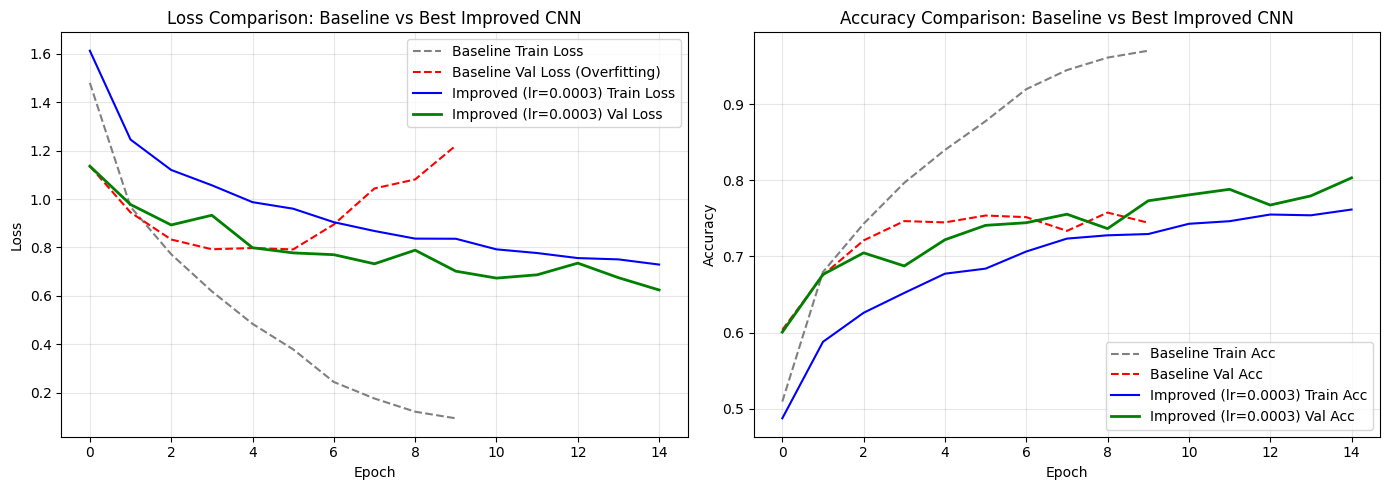

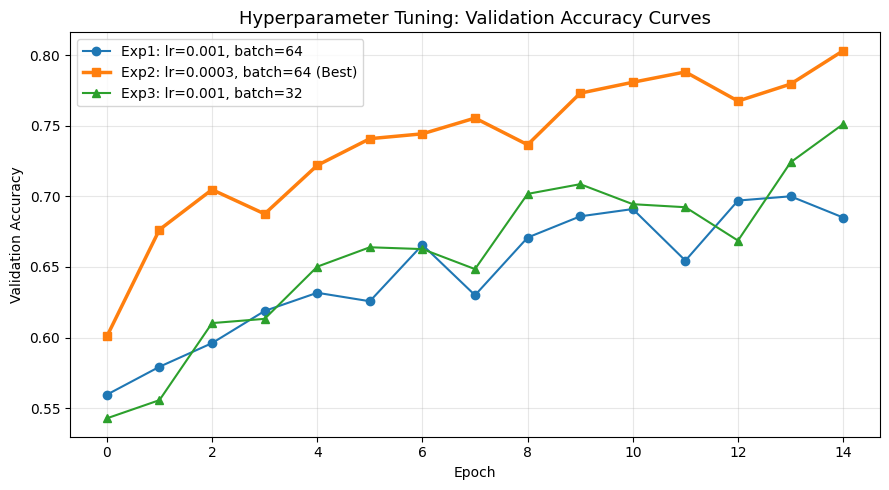


🏆 최종 선택 모델 [Exp2_Lower_LR]의 Test 데이터셋 최종 정확도: 0.8054 (80.54%)


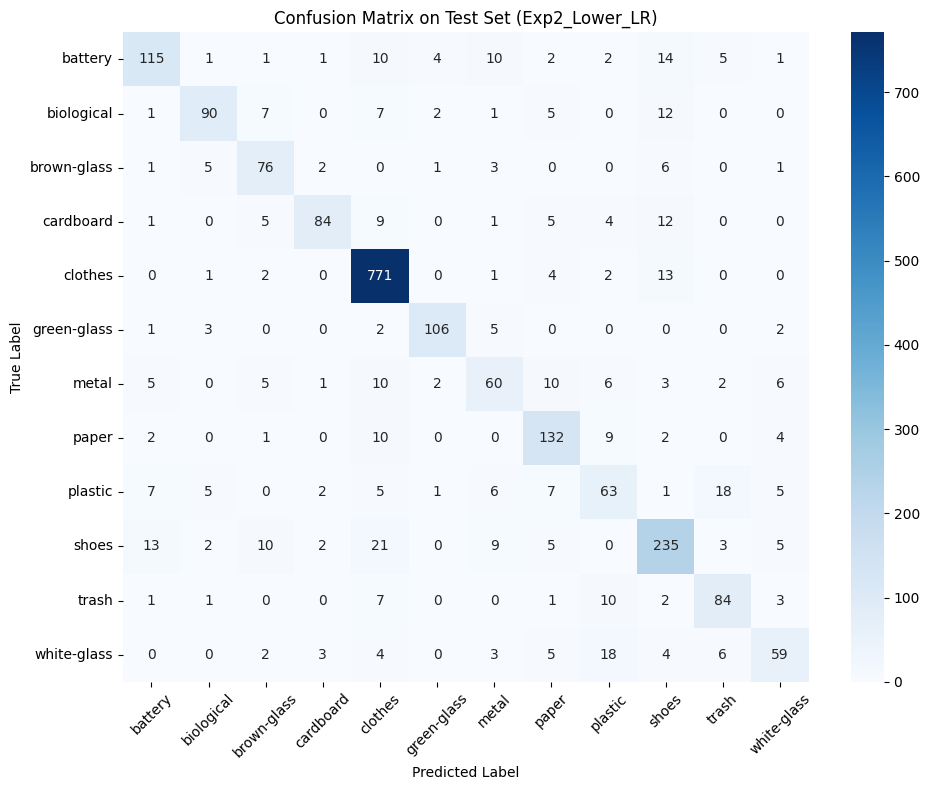

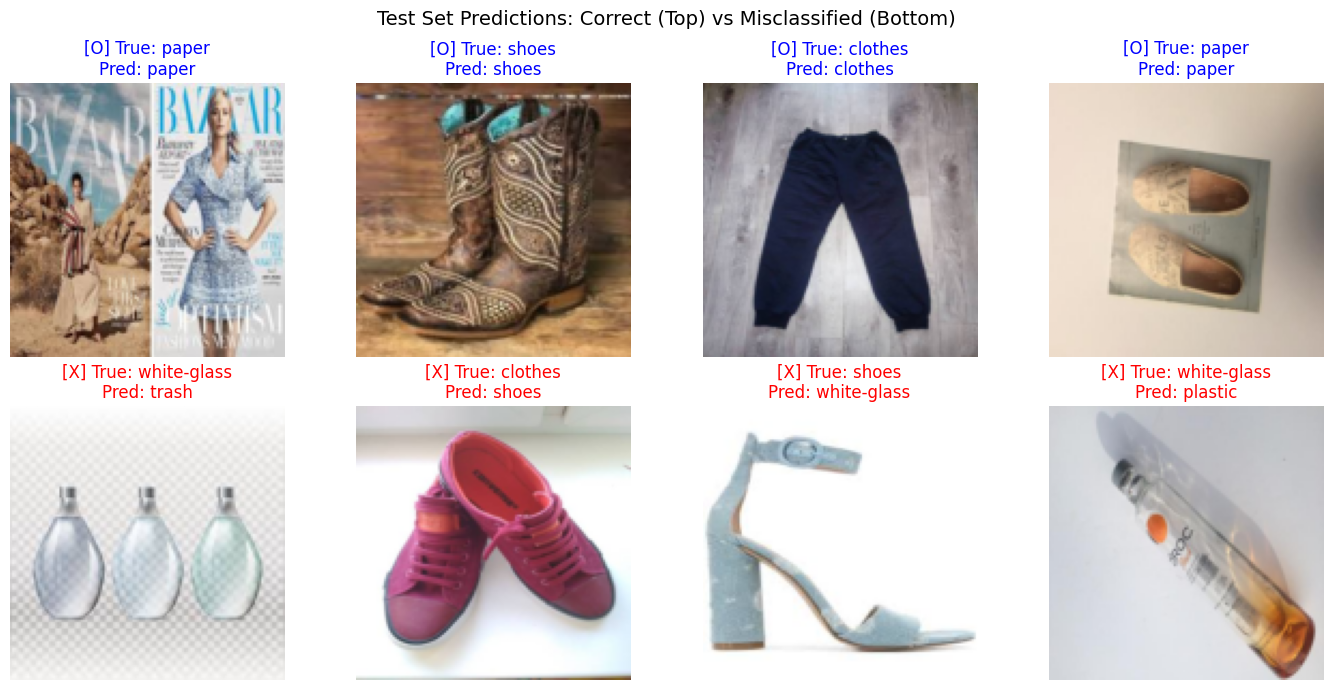

In [4]:
# 1. [보고서 그림 4] Baseline(과적합) vs 최고 개선 모델(Exp2_Lower_LR) 학습 곡선 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Baseline Train Loss", linestyle="--", color="gray")
axes[0].plot(history["val_loss"], label="Baseline Val Loss (Overfitting)", linestyle="--", color="red")
axes[0].plot(histories["Exp2_Lower_LR"]["train_loss"], label="Improved (lr=0.0003) Train Loss", color="blue")
axes[0].plot(histories["Exp2_Lower_LR"]["val_loss"], label="Improved (lr=0.0003) Val Loss", color="green", linewidth=2)
axes[0].set_title("Loss Comparison: Baseline vs Best Improved CNN")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history["train_acc"], label="Baseline Train Acc", linestyle="--", color="gray")
axes[1].plot(history["val_acc"], label="Baseline Val Acc", linestyle="--", color="red")
axes[1].plot(histories["Exp2_Lower_LR"]["train_acc"], label="Improved (lr=0.0003) Train Acc", color="blue")
axes[1].plot(histories["Exp2_Lower_LR"]["val_acc"], label="Improved (lr=0.0003) Val Acc", color="green", linewidth=2)
axes[1].set_title("Accuracy Comparison: Baseline vs Best Improved CNN")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. [보고서 그림 5] 하이퍼파라미터 3가지 실험 검증 정확도 비교 곡선
plt.figure(figsize=(9, 5))
plt.plot(histories["Exp1_Improved_Base"]["val_acc"], label="Exp1: lr=0.001, batch=64", marker="o")
plt.plot(histories["Exp2_Lower_LR"]["val_acc"], label="Exp2: lr=0.0003, batch=64 (Best)", marker="s", linewidth=2.5)
plt.plot(histories["Exp3_Batch32"]["val_acc"], label="Exp3: lr=0.001, batch=32", marker="^")
plt.title("Hyperparameter Tuning: Validation Accuracy Curves", fontsize=13)
plt.xlabel("Epoch"); plt.ylabel("Validation Accuracy"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. [보고서 그림 6] 최종 모델(Exp2_Lower_LR) Test 평가 및 혼동 행렬
best_model = models["Exp2_Lower_LR"]
test_loader_clean = DataLoader(test_ds_clean, batch_size=64, shuffle=False)
best_model.eval()

all_preds, all_labels = [], []
correct_imgs, correct_preds, correct_labels = [], [], []
wrong_imgs, wrong_preds, wrong_labels = [], [], []

with torch.no_grad():
    for bx, by in test_loader_clean:
        out = best_model(bx.to(device))
        preds = out.argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(by.numpy())

        for i in range(len(by)):
            if preds[i] == by[i] and len(correct_imgs) < 4:
                correct_imgs.append(bx[i]); correct_preds.append(preds[i].item()); correct_labels.append(by[i].item())
            elif preds[i] != by[i] and len(wrong_imgs) < 4:
                wrong_imgs.append(bx[i]); wrong_preds.append(preds[i].item()); wrong_labels.append(by[i].item())

test_acc = (np.array(all_preds) == np.array(all_labels)).mean()
print(f"\n🏆 최종 선택 모델 [Exp2_Lower_LR]의 Test 데이터셋 최종 정확도: {test_acc:.4f} ({test_acc*100:.2f}%)")

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix on Test Set (Exp2_Lower_LR)")
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. [보고서 그림 7] 맞춘 이미지 vs 틀린 이미지 시각화
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(correct_imgs[i].permute(1, 2, 0).numpy())
    axes[0, i].set_title(f"[O] True: {class_names[correct_labels[i]]}\nPred: {class_names[correct_preds[i]]}", color="blue")
    axes[0, i].axis("off")

    axes[1, i].imshow(wrong_imgs[i].permute(1, 2, 0).numpy())
    axes[1, i].set_title(f"[X] True: {class_names[wrong_labels[i]]}\nPred: {class_names[wrong_preds[i]]}", color="red")
    axes[1, i].axis("off")

plt.suptitle("Test Set Predictions: Correct (Top) vs Misclassified (Bottom)", fontsize=14)
plt.tight_layout()
plt.show()